In [ ]:
# =====================================================================================
#  CELL 1 — CONFIGURATION.  This is the only cell you need to edit.
# =====================================================================================
class CFG:
    # ------------------------------------------------------------------ what to run
    DATASETS = ["ember2018", "ember2024"]          # run both datasets, or only one of them

    # ------------------------------------------------------------- number of samples
    EMBER2018_N_TRAIN = None     # labelled EMBER-2018 training files to use (None = all)
    EMBER2018_N_TEST  = None     # labelled EMBER-2018 test files to use     (None = all)
    EMBER2024_N_TRAIN = None     # labelled EMBER-2024 training files to use (None = all)
    EMBER2024_N_TEST  = None     # labelled EMBER-2024 test files to use     (None = all)

    # ------------------------------------------------------------------------- paths
    DRIVE_ROOT = "/content/drive/MyDrive"
    EMBER2018_TRAIN_DIR   = DRIVE_ROOT + "/dataset/Win64_train"     # EMBER-2018 training files
    EMBER2018_TEST_DIR    = DRIVE_ROOT + "/dataset/Win64_test"      # EMBER-2018 test files
    EMBER2018_CACHE_DIR   = DRIVE_ROOT + "/cache/ember2018"         # used for raw .jsonl input only
    EMBER2024_TRAIN_ZIP   = DRIVE_ROOT + "/EMBER-2024/Win64_train.zip"   # weekly raw .jsonl files (training)
    EMBER2024_TEST_ZIP    = DRIVE_ROOT + "/EMBER-2024/Win64_test.zip"    # weekly raw .jsonl files (test)
    EMBER2024_EXTRACT_DIR = "/content/ember2024"                               # the archives are unpacked here
    EMBER2024_CACHE_DIR   = DRIVE_ROOT + "/cache/ember2024"         # vectorised arrays; the same folder as
    #                                                                            in the EMBER-2024 XAI notebook, so
    #                                                                            vectors made there are reused
    OUTPUT_DIR = DRIVE_ROOT + "/results/training_cost"              # CSV files and figures
    WORK_DIR   = "/content/training_cost_work"                                 # local disk: arrays for the training runs

    # ---------------------------------------- removal order, from the LEAST to the MOST important group
    # Taken from the EMBER-XAI ablation files (column `last_group_imputed` of ablation_xgboost.csv).
    REMOVAL_ORDER = {
        "ember2018": ["exports", "general", "strings", "header", "histogram", "byteentropy", "imports", "section",
                      "datadirectories"],
        "ember2024": ["general", "ttps", "exports", "caps", "mbc", "richheader", "byteentropy", "pefilewarnings",
                      "histogram", "authenticode", "section", "datadirectories", "header", "imports", "strings"],
    }
    # Optional: path of an ablation CSV to read the order from instead (None = use REMOVAL_ORDER above).
    ABLATION_CSV = {"ember2018": None, "ember2024": None}
    # Stop removing groups when this many are left (1 = remove groups until one group is left).
    MIN_GROUPS_RETAINED = {"ember2018": 1, "ember2024": 1}

    # ------------------------------------------------------ classifier (XGBoost on the GPU, one seed)
    SEED                  = 2026
    LEARNING_RATE         = 0.05
    XGB_MAX_DEPTH         = 8
    MAX_BIN               = 256
    NUM_BOOST_ROUND       = 1000
    EARLY_STOPPING_ROUNDS = 0      # 0 = every feature set is trained for NUM_BOOST_ROUND rounds, so the cost of two
    #                                feature sets can be compared directly. A value above 0 turns early stopping on.
    VAL_FRACTION          = 0.10   # validation split, used only when early stopping is on

    # ------------------------------------------------------------------- measurement
    MEMORY_METRIC      = "gpu"     # memory shown in the figures: "gpu", "host" or "total" (GPU + host)
    TIME_METRIC        = "train"   # time shown in the figures: "train" (quantised matrix + boosting) or
    #                                "total" (the host-to-GPU copy is added)
    MONITOR_INTERVAL_S = 0.05      # seconds between two memory readings
    UPLOAD_CHUNK_ROWS  = 50_000    # rows per host-to-GPU copy
    PRED_BATCH_ROWS    = 100_000   # test rows per prediction call
    REQUIRE_GPU_NAME   = None      # e.g. "A100": stop if the GPU name does not contain this text (None = any GPU)

    # ------------------------------------------------------------------- run control
    RESUME    = True     # reuse the runs already saved in OUTPUT_DIR for the same settings
    DATA_SEED = 0        # seed of the sub-sampling done while loading (the N_TRAIN / N_TEST settings)
    N_WORKERS = None     # processes used to vectorise raw .jsonl files (None = all CPU cores)
    LOG_EVERY = 250      # print the progress every this many boosting rounds (0 = silent)

    # ----------------------------------------------------------------------- dataset
    # EMBER-2018 (feature version 2): 9 groups and 2,381 columns, in this order.
    EMBER2018_FEATURE_GROUPS = [
        ("histogram", 256), ("byteentropy", 256), ("strings", 104), ("general", 10), ("header", 62),
        ("section", 255), ("imports", 1280), ("exports", 128), ("datadirectories", 30),
    ]
    # EMBER-2024 (Windows PE): the 15 static feature groups, as in the EMBER-2024 XAI notebook.
    EMBER2024_FEATURE_GROUPS = [
        "general", "histogram", "byteentropy", "strings", "header", "section", "imports", "exports",
        "datadirectories", "richheader", "authenticode", "pefilewarnings", "caps", "ttps", "mbc",
    ]
    # Tags derived from antivirus results. They are metadata and are never read as features.
    EMBER2024_EXCLUDED_AV_TAGS = ["behavior", "packer", "file_property", "exploit", "group"]
    # Number of hash buckets used to vectorise the capa results (caps, ttps, mbc).
    EMBER2024_CAPA_HASH_DIMS = {"capability": 256, "namespace": 64, "tactic": 32, "technique": 128,
                                "objective": 32, "behavior": 128}

    # ----------------------------------------------------------------------- figures
    FIG_FONT_FAMILY  = "serif"
    FIG_FONT_SIZE    = 12
    FIG_DPI          = 600
    FIG_FORMATS      = ("pdf", "png")
    FIG_SIZE         = (5.6, 3.9)       # inches, one dataset
    COLOR_TIME       = "#0072B2"        # training time: colour-blind-safe blue, solid line, circles
    COLOR_MEMORY     = "#D55E00"        # memory usage: colour-blind-safe vermillion, dashed line, squares
    TIME_UNIT        = "auto"           # "seconds", "minutes" or "auto" (minutes when a run takes 2 minutes or more)
    Y_AXES_FROM_ZERO = False            # True: both vertical axes start at 0

In [ ]:
import os, sys, subprocess, importlib, importlib.util, importlib.metadata as _md

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")


def _installed(dist):
    try:
        return _md.version(dist)
    except _md.PackageNotFoundError:
        return None


def _pip(*specs, required=True):
    r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", *specs])
    if r.returncode != 0 and required:
        raise RuntimeError(f"pip install failed for {specs}")
    importlib.invalidate_caches()


def _gpu_query(fields):
    """Reads fields of GPU 0 from the driver. This notebook process itself never uses the GPU."""
    try:
        r = subprocess.run(["nvidia-smi", "--id=0", f"--query-gpu={fields}", "--format=csv,noheader,nounits"],
                           capture_output=True, text=True)
        ok = r.returncode == 0 and r.stdout.strip() != ""
    except FileNotFoundError:
        ok = False
    if not ok:
        raise RuntimeError("No NVIDIA GPU found. This notebook runs on the GPU only: choose "
                           "Runtime -> Change runtime type -> GPU and run it again.")
    return [v.strip() for v in r.stdout.strip().splitlines()[0].split(",")]


GPU_NAME, _total_mib = _gpu_query("name,memory.total")
GPU_TOTAL_GB = float(_total_mib) / 1024.0
print(f"GPU: {GPU_NAME} ({GPU_TOTAL_GB:.0f} GB)")
if CFG.REQUIRE_GPU_NAME and CFG.REQUIRE_GPU_NAME not in GPU_NAME:
    raise RuntimeError(f"CFG.REQUIRE_GPU_NAME = {CFG.REQUIRE_GPU_NAME!r}, but the runtime has '{GPU_NAME}'.")

_v = _installed("xgboost")
if _v is None or tuple(int(t) for t in _v.split(".")[:2]) < (2, 1):
    _pip("xgboost>=2.1")                       # device="cuda" and GPU input need a recent XGBoost
if importlib.util.find_spec("cupy") is None:
    _pip("cupy-cuda12x")                       # GPU arrays that are handed to XGBoost
if importlib.util.find_spec("pynvml") is None:
    _pip("nvidia-ml-py", required=False)       # fast GPU memory readings (nvidia-smi is used without it)
if _installed("psutil") is None:
    _pip("psutil")
if _installed("orjson") is None:
    _pip("orjson", required=False)             # optional: faster JSON parsing of the raw .jsonl files
if _installed("tqdm") is None:
    _pip("tqdm")

_dirs = [CFG.OUTPUT_DIR, CFG.WORK_DIR]
if "ember2018" in CFG.DATASETS:
    _dirs += [CFG.EMBER2018_CACHE_DIR]
if "ember2024" in CFG.DATASETS:
    _dirs += [CFG.EMBER2024_CACHE_DIR, CFG.EMBER2024_EXTRACT_DIR]
for _d in _dirs:
    os.makedirs(_d, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: NVIDIA A100-SXM4-40GB (40 GB)


In [ ]:
import gc, glob, hashlib, json, math, re, shutil, time, zipfile
import multiprocessing as mp

import numpy as np
import pandas as pd
import xgboost as xgb
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

print(f"xgboost {xgb.__version__} | numpy {np.__version__} | pandas {pd.__version__}")
if not xgb.build_info().get("USE_CUDA", True):
    raise RuntimeError("This XGBoost build has no GPU support. Install the standard wheel: pip install -U xgboost")

DATASET_TITLE = {"ember2018": "EMBER-2018", "ember2024": "EMBER-2024"}
_bad = sorted(set(CFG.DATASETS) - set(DATASET_TITLE))
if _bad:
    raise ValueError(f"unknown names in CFG.DATASETS: {_bad}; choose from {sorted(DATASET_TITLE)}")
assert CFG.MEMORY_METRIC in ("gpu", "host", "total") and CFG.TIME_METRIC in ("train", "total")
RESULTS = {}                 # dataset name -> table with one row per training run


def stratified_indices(y, n, rng):
    """Sorted indices of a class-stratified random sample of size n (all indices if n is None or too large)."""
    y = np.asarray(y)
    if n is None or n >= len(y):
        return np.arange(len(y))
    classes, counts = np.unique(y, return_counts=True)
    exact = counts * (n / len(y))
    alloc = np.floor(exact).astype(int)
    for j in np.argsort(-(exact - alloc))[: n - alloc.sum()]:
        alloc[j] += 1
    picks = [rng.choice(np.flatnonzero(y == c), size=a, replace=False) for c, a in zip(classes, alloc)]
    return np.sort(np.concatenate(picks))


def slices_of(dims):
    """Column slice of every group, and the total number of columns."""
    off = np.concatenate([[0], np.cumsum(dims)]).astype(int)
    return [slice(int(off[i]), int(off[i + 1])) for i in range(len(dims))], int(off[-1])


# ---- the training process ---------------------------------------------------------
WORKER_SOURCE = r'''"""Trains one XGBoost classifier on the GPU in a fresh process and reports its cost.

The notebook writes this file and runs it once per feature set:  python train_worker.py <job.json>
A fresh process per feature set keeps the measurements independent of each other: nothing that an earlier,
larger run left in a cache can hide memory that a later, smaller run needs.
"""
import json, sys, threading, time, traceback

import numpy as np
import psutil


def make_gpu_reader(index):
    """Returns a function that reads the memory in use on the GPU (GB) from the driver, and the name of the source."""
    try:
        import pynvml
        pynvml.nvmlInit()
        handle = pynvml.nvmlDeviceGetHandleByIndex(index)
        read = lambda: pynvml.nvmlDeviceGetMemoryInfo(handle).used / 2**30
        read()
        return read, "nvml"
    except Exception:
        import subprocess
        cmd = ["nvidia-smi", f"--id={index}", "--query-gpu=memory.used", "--format=csv,noheader,nounits"]
        read = lambda: float(subprocess.check_output(cmd, text=True).split()[0]) / 1024.0
        read()
        return read, "nvidia-smi"


_PROCESS = psutil.Process()


def host_gb():
    """Host memory of this process (GB), without the pages of memory-mapped files (they belong to the page cache)."""
    m = _PROCESS.memory_info()
    return (m.rss - getattr(m, "shared", 0)) / 2**30


class PeakMonitor(threading.Thread):
    """Samples GPU and host memory in the background and keeps the largest values seen."""

    def __init__(self, read_gpu, interval):
        super().__init__(daemon=True)
        self.read_gpu, self.interval = read_gpu, interval
        self.halt, self.lock = threading.Event(), threading.Lock()
        self.gpu0 = read_gpu()               # GPU memory in use before this process touches the GPU
        self.gpu, self.host, self.total, self.samples = self.gpu0, host_gb(), self.gpu0 + host_gb(), 0

    def sample(self):
        g, h = self.read_gpu(), host_gb()
        with self.lock:
            self.gpu, self.host, self.total = max(self.gpu, g), max(self.host, h), max(self.total, g + h)
            self.samples += 1

    def run(self):
        while not self.halt.is_set():
            self.sample()
            self.halt.wait(self.interval)

    def stop(self):
        self.halt.set()
        self.join()
        self.sample()


def main(job):
    read_gpu, source = make_gpu_reader(job["gpu_index"])
    monitor = PeakMonitor(read_gpu, job["monitor_interval_s"])

    import cupy as cp
    import xgboost as xgb

    # No CuPy memory pool: freed GPU memory goes back to the driver at once, so the readings show what is in use.
    cp.cuda.set_allocator(None)
    cp.cuda.set_pinned_memory_allocator(None)
    sync = cp.cuda.Stream.null.synchronize

    params = dict(objective="binary:logistic", eval_metric="logloss", tree_method="hist", device="cuda",
                  learning_rate=job["learning_rate"], max_depth=job["max_depth"], max_bin=job["max_bin"],
                  seed=job["seed"], verbosity=1)

    # Warm-up, not timed: creates the CUDA context and loads XGBoost's GPU code.
    warm = cp.asarray(np.random.default_rng(0).random((4096, 16), dtype=np.float32))
    xgb.train(dict(params, verbosity=0),
              xgb.QuantileDMatrix(warm, label=(np.arange(4096) % 2).astype(np.float32), max_bin=job["max_bin"]),
              num_boost_round=3)
    del warm
    sync()

    X = np.load(job["x_train"], mmap_mode="r")
    y = np.load(job["y_train"]).astype(np.float32)
    cols = np.asarray(job["columns"], dtype=np.int64)
    fit_rows = np.load(job["fit_rows"]) if job.get("fit_rows") else None
    val_rows = np.load(job["val_rows"]) if job.get("val_rows") else None

    def to_gpu(src, rows=None):
        """Copies the retained columns to the GPU chunk by chunk (the matrix is never copied in host memory)."""
        n = src.shape[0] if rows is None else len(rows)
        out = cp.empty((n, len(cols)), dtype=cp.float32)
        step = job["upload_chunk_rows"]
        for a in range(0, n, step):
            block = src[a:a + step] if rows is None else src[rows[a:a + step]]
            out[a:a + step] = cp.asarray(np.ascontiguousarray(block[:, cols], dtype=np.float32))
        return out

    monitor.start()

    # 1. host -> GPU copy of the retained columns
    t0 = time.perf_counter()
    X_fit = to_gpu(X, fit_rows)
    X_val = to_gpu(X, val_rows) if val_rows is not None else None
    sync()
    t_transfer = time.perf_counter() - t0

    # 2. quantised training matrix, built on the GPU
    t0 = time.perf_counter()
    dtrain = xgb.QuantileDMatrix(X_fit, label=y if fit_rows is None else y[fit_rows], max_bin=job["max_bin"])
    evals = []
    if X_val is not None:
        evals = [(xgb.QuantileDMatrix(X_val, label=y[val_rows], ref=dtrain), "val")]
    sync()
    t_dmatrix = time.perf_counter() - t0
    monitor.sample()                         # the raw and the quantised matrix are both on the GPU here
    del X_fit, X_val

    # 3. boosting
    rounds, log_every = job["num_boost_round"], job["log_every"]

    class Progress(xgb.callback.TrainingCallback):
        def after_iteration(self, model, epoch, evals_log):
            if log_every and (epoch + 1) % log_every == 0:
                print(f"round {epoch + 1}/{rounds}", flush=True)
            return False

    t0 = time.perf_counter()
    booster = xgb.train(params, dtrain, num_boost_round=rounds, evals=evals,
                        early_stopping_rounds=job["early_stopping_rounds"] or None, verbose_eval=False,
                        callbacks=[Progress()])
    sync()
    t_boost = time.perf_counter() - t0
    monitor.stop()

    used = json.loads(booster.save_config())["learner"]["generic_param"]["device"]
    if not str(used).startswith("cuda"):
        raise RuntimeError(f"XGBoost trained on '{used}' instead of the GPU. This experiment is GPU only.")
    n_trees = booster.best_iteration + 1 if evals else booster.num_boosted_rounds()

    # 4. quality of the retrained model on the test files (on the GPU; not part of the time or memory readings)
    del dtrain, evals
    X_te = np.load(job["x_test"], mmap_mode="r")
    y_te = np.load(job["y_test"])
    preds = []
    for a in range(0, X_te.shape[0], job["pred_batch_rows"]):
        xb = cp.asarray(np.ascontiguousarray(X_te[a:a + job["pred_batch_rows"]][:, cols], dtype=np.float32))
        p = booster.inplace_predict(xb, iteration_range=(0, n_trees))
        preds.append(p if isinstance(p, np.ndarray) else cp.asnumpy(p))
    p = np.clip(np.concatenate(preds).astype(np.float64), 1e-7, 1 - 1e-7)
    from sklearn.metrics import average_precision_score, roc_auc_score

    return {
        "transfer_time_s": t_transfer, "dmatrix_time_s": t_dmatrix, "boost_time_s": t_boost,
        "train_time_s": t_dmatrix + t_boost, "total_time_s": t_transfer + t_dmatrix + t_boost,
        "gpu_mem_peak_gb": monitor.gpu - monitor.gpu0, "host_mem_peak_gb": monitor.host,
        "total_mem_peak_gb": monitor.total - monitor.gpu0, "gpu_mem_baseline_gb": monitor.gpu0,
        "memory_source": source, "memory_samples": monitor.samples,
        "n_trees": int(n_trees), "n_fit_rows": int(X.shape[0] if fit_rows is None else len(fit_rows)),
        "test_auroc": float(roc_auc_score(y_te, p)), "test_auprc": float(average_precision_score(y_te, p)),
        "test_ce_bits": float(-(y_te * np.log2(p) + (1 - y_te) * np.log2(1 - p)).mean()),
        "device": str(used), "xgboost_version": xgb.__version__, "cupy_version": cp.__version__,
    }


if __name__ == "__main__":
    with open(sys.argv[1]) as fh:
        job = json.load(fh)
    try:
        result = main(job)
    except Exception:
        result = {"error": traceback.format_exc()}
    with open(job["result_path"], "w") as fh:
        json.dump(result, fh)
    sys.exit(1 if "error" in result else 0)
'''
WORKER_PATH = os.path.join(CFG.WORK_DIR, "train_worker.py")
with open(WORKER_PATH, "w") as _fh:
    _fh.write(WORKER_SOURCE)


def run_worker(job, quiet=False):
    """Starts one training process, shows its output and returns its measurements."""
    job_path = os.path.join(CFG.WORK_DIR, "job.json")
    job = dict(job, result_path=os.path.join(CFG.WORK_DIR, "result.json"), gpu_index=0,
               learning_rate=CFG.LEARNING_RATE, max_depth=CFG.XGB_MAX_DEPTH, max_bin=CFG.MAX_BIN, seed=CFG.SEED,
               monitor_interval_s=CFG.MONITOR_INTERVAL_S, upload_chunk_rows=CFG.UPLOAD_CHUNK_ROWS,
               pred_batch_rows=CFG.PRED_BATCH_ROWS, log_every=0 if quiet else CFG.LOG_EVERY)
    if os.path.exists(job["result_path"]):
        os.remove(job["result_path"])
    with open(job_path, "w") as fh:
        json.dump(job, fh)
    proc = subprocess.Popen([sys.executable, "-u", WORKER_PATH, job_path], stdout=subprocess.PIPE,
                            stderr=subprocess.STDOUT, text=True)
    tail = []
    for line in proc.stdout:
        tail = (tail + [line.rstrip()])[-40:]
        if not quiet and line.strip():
            print("      " + line.rstrip(), flush=True)
    proc.wait()
    if os.path.exists(job["result_path"]):
        with open(job["result_path"]) as fh:
            result = json.load(fh)
    else:
        result = {"error": "the training process ended without a result (exit code "
                           f"{proc.returncode}).\n" + "\n".join(tail)}
    if "error" in result:
        hint = ("\nThe GPU ran out of memory. Lower the N_TRAIN setting of this dataset in Cell 1."
                if "out of memory" in result["error"].lower() else "")
        raise RuntimeError("The training process failed:\n" + result["error"] + hint)
    return result


# ---- the experiment plan ----------------------------------------------------------
def sample_counts(name):
    return ((CFG.EMBER2018_N_TRAIN, CFG.EMBER2018_N_TEST) if name == "ember2018"
            else (CFG.EMBER2024_N_TRAIN, CFG.EMBER2024_N_TEST))


def removal_order(name, group_names):
    """Groups from the least to the most important one, from CFG.ABLATION_CSV or CFG.REMOVAL_ORDER."""
    path = CFG.ABLATION_CSV.get(name)
    if path:
        col = pd.read_csv(path)["last_group_imputed"]
        order = [str(g) for g in col if isinstance(g, str) and g.strip()]
    else:
        order = list(CFG.REMOVAL_ORDER[name])
    if sorted(order) != sorted(group_names):
        raise ValueError(f"The removal order of {name} must list every feature group exactly once.\n"
                         f"  order : {order}\n  groups: {list(group_names)}")
    return order


def make_plan(name, group_names, group_dims):
    """The feature sets of one dataset (all groups, then one group fewer per step) and the runs already saved."""
    group_names, group_dims = list(group_names), [int(d) for d in group_dims]
    slices, _ = slices_of(group_dims)
    order = removal_order(name, group_names)
    n_groups = len(group_names)
    keep_min = min(n_groups, max(1, int(CFG.MIN_GROUPS_RETAINED.get(name, 1))))
    steps = []
    for k in range(n_groups - keep_min + 1):
        kept = [g for g in group_names if g not in order[:k]]            # dataset column order is kept
        cols = np.concatenate([np.arange(slices[group_names.index(g)].start, slices[group_names.index(g)].stop)
                               for g in kept])
        steps.append({"n_groups_retained": n_groups - k, "n_groups_removed": k,
                      "removed_group": order[k - 1] if k else "", "retained_groups": kept, "columns": cols})
    early = int(CFG.EARLY_STOPPING_ROUNDS or 0)
    paths = ([CFG.EMBER2018_TRAIN_DIR, CFG.EMBER2018_TEST_DIR] if name == "ember2018"
             else [CFG.EMBER2024_TRAIN_ZIP, CFG.EMBER2024_TEST_ZIP, CFG.EMBER2024_CAPA_HASH_DIMS])
    key = [name, paths, list(sample_counts(name)), CFG.DATA_SEED, CFG.SEED, CFG.LEARNING_RATE, CFG.XGB_MAX_DEPTH,
           CFG.MAX_BIN, CFG.NUM_BOOST_ROUND, early, CFG.VAL_FRACTION if early else None, order, group_names,
           group_dims, GPU_NAME, xgb.__version__]
    signature = hashlib.md5(json.dumps(key).encode()).hexdigest()[:10]
    csv_path = os.path.join(CFG.OUTPUT_DIR, f"training_cost_{name}_xgboost.csv")
    done = {}
    if os.path.exists(csv_path):
        old = pd.read_csv(csv_path, keep_default_na=False)
        same = old[old["settings"] == signature] if "settings" in old.columns else old.iloc[:0]
        if CFG.RESUME:
            done = {int(r["n_groups_retained"]): r for r in same.to_dict("records")}
        if len(same) < len(old) or not CFG.RESUME:                      # keep results made with other settings
            backup = csv_path.replace(".csv", time.strftime("_backup_%Y%m%d_%H%M%S.csv"))
            shutil.copy(csv_path, backup)
            print(f"  [{DATASET_TITLE[name]}] earlier results with other settings were copied to {backup}")
    todo = [s for s in steps if s["n_groups_retained"] not in done]
    print(f"[{DATASET_TITLE[name]}] {len(steps)} feature sets, from {n_groups} down to {keep_min} group(s); "
          f"{len(steps) - len(todo)} already saved, {len(todo)} to train.")
    print("  removal order (least important first):", ", ".join(order))
    return {"name": name, "steps": steps, "todo": todo, "done": done, "signature": signature, "csv": csv_path}


def stage_dataset(name, X_train, y_train, X_test, y_test):
    """Writes the arrays to the local disk, where the training processes read them (memory-mapped)."""
    folder = os.path.join(CFG.WORK_DIR, name)
    shutil.rmtree(folder, ignore_errors=True)
    os.makedirs(folder)
    need, free = X_train.nbytes + X_test.nbytes, shutil.disk_usage(folder).free
    if need > 0.95 * free:
        raise OSError(f"{name}: {need / 2**30:.1f} GB are needed in {CFG.WORK_DIR}, but only "
                      f"{free / 2**30:.1f} GB are free. Lower the number of samples or change CFG.WORK_DIR.")
    stage = {"n_train": int(len(y_train)), "n_test": int(len(y_test)), "n_features": int(X_train.shape[1])}
    for key, arr in (("x_train", X_train), ("y_train", y_train), ("x_test", X_test), ("y_test", y_test)):
        stage[key] = os.path.join(folder, key + ".npy")
        np.save(stage[key], np.ascontiguousarray(arr))
    if CFG.EARLY_STOPPING_ROUNDS:
        from sklearn.model_selection import train_test_split
        fit, val = train_test_split(np.arange(len(y_train)), test_size=CFG.VAL_FRACTION, stratify=y_train,
                                    random_state=CFG.SEED)
        for key, rows in (("fit_rows", fit), ("val_rows", val)):
            stage[key] = os.path.join(folder, key + ".npy")
            np.save(stage[key], np.sort(rows))
    print(f"  staged {need / 2**30:.2f} GB in {folder}")
    return stage


def save_results(plan):
    """Writes the finished runs of one dataset to its CSV file and returns the runs of the current plan."""
    rows = [plan["done"][k] for k in sorted(plan["done"], reverse=True)]
    table = pd.DataFrame(rows)
    if len(table):
        table.to_csv(plan["csv"], index=False)             # the file keeps every finished run
        wanted = [s["n_groups_retained"] for s in plan["steps"]]
        table = table[table["n_groups_retained"].isin(wanted)].reset_index(drop=True)
    return table


def run_steps(plan, stage):
    """Trains every feature set of the plan that is not saved yet, one fresh GPU process per feature set."""
    title = DATASET_TITLE[plan["name"]]
    for i, step in enumerate(plan["todo"], 1):
        removed = f", '{step['removed_group']}' removed" if step["removed_group"] else ", all groups"
        print(f"  [{title}] run {i}/{len(plan['todo'])}: {step['n_groups_retained']} groups retained "
              f"({len(step['columns']):,} columns{removed})", flush=True)
        job = {k: stage[k] for k in ("x_train", "y_train", "x_test", "y_test")}
        job.update(columns=step["columns"].tolist(), num_boost_round=CFG.NUM_BOOST_ROUND,
                   early_stopping_rounds=int(CFG.EARLY_STOPPING_ROUNDS or 0),
                   fit_rows=stage.get("fit_rows"), val_rows=stage.get("val_rows"))
        res = run_worker(job)
        row = {"dataset": plan["name"], "model": "xgboost", "n_groups_retained": step["n_groups_retained"],
               "n_groups_removed": step["n_groups_removed"], "removed_group": step["removed_group"],
               "retained_groups": ";".join(step["retained_groups"]), "n_features": len(step["columns"]),
               "n_train": stage["n_train"], "n_test": stage["n_test"], "seed": CFG.SEED,
               "num_boost_round": CFG.NUM_BOOST_ROUND}
        row.update(res)
        row.update(gpu_name=GPU_NAME, settings=plan["signature"])
        plan["done"][step["n_groups_retained"]] = row
        save_results(plan)                                   # the file is complete after every run
        print(f"      training time {res['train_time_s']:8.1f} s | GPU memory {res['gpu_mem_peak_gb']:6.2f} GB | "
              f"host memory {res['host_mem_peak_gb']:5.2f} GB | test AUROC {res['test_auroc']:.4f} | "
              f"test AUPRC {res['test_auprc']:.4f}", flush=True)
    plan["todo"] = []
    return save_results(plan)


# ---- self-test of the GPU path on random data -------------------------------------
def gpu_self_test():
    folder = os.path.join(CFG.WORK_DIR, "_selftest")
    shutil.rmtree(folder, ignore_errors=True)
    os.makedirs(folder)
    rng = np.random.default_rng(0)
    X = rng.random((20_000, 64), dtype=np.float32)
    y = (X[:, 0] + X[:, 1] * X[:, 2] + 0.3 * rng.normal(size=len(X)) > 1.0).astype(np.int8)
    job = {}
    for key, arr in (("x_train", X[:16_000]), ("y_train", y[:16_000]), ("x_test", X[16_000:]), ("y_test", y[16_000:])):
        job[key] = os.path.join(folder, key + ".npy")
        np.save(job[key], arr)
    job.update(columns=list(range(8, 64)) + [0, 1, 2], num_boost_round=20, early_stopping_rounds=0,
               fit_rows=None, val_rows=None)
    res = run_worker(job, quiet=True)
    shutil.rmtree(folder, ignore_errors=True)
    print(f"GPU self-test passed: XGBoost {res['xgboost_version']} trained on '{res['device']}' with CuPy "
          f"{res['cupy_version']}; memory read through {res['memory_source']} ({res['memory_samples']} readings, "
          f"peak {res['gpu_mem_peak_gb']:.2f} GB); test AUROC {res['test_auroc']:.3f}.")
    if res["memory_samples"] < 3 or not res["gpu_mem_peak_gb"] > 0:
        print("WARNING: the GPU memory readings look wrong (no increase was seen during the self-test).")


gpu_self_test()

xgboost 3.4.1 | numpy 2.4.6 | pandas 2.2.3
GPU self-test passed: XGBoost 3.4.1 trained on 'cuda:0' with CuPy 14.0.1; memory read through nvml (5 readings, peak 0.59 GB); test AUROC 0.872.


In [ ]:
# ---- the grouped-feature setting of EMBER-2018 -----------------------------------
GROUP_NAMES = [name for name, _ in CFG.EMBER2018_FEATURE_GROUPS]
GROUP_DIMS = [dim for _, dim in CFG.EMBER2018_FEATURE_GROUPS]
GROUP_SLICES, N_FEATURES = slices_of(GROUP_DIMS)

try:
    import orjson
    _loads = orjson.loads
except Exception:
    _loads = json.loads

from sklearn.feature_extraction import FeatureHasher

_HASHERS = {}
_RAW_GROUPS = ["histogram", "byteentropy", "strings", "general", "header", "section", "imports", "exports",
               "datadirectories"]
_GENERAL_KEYS = ["size", "vsize", "has_debug", "exports", "imports", "has_relocations", "has_resources",
                 "has_signature", "has_tls", "symbols"]
_OPTIONAL_KEYS = ["major_image_version", "minor_image_version", "major_linker_version", "minor_linker_version",
                  "major_operating_system_version", "minor_operating_system_version", "major_subsystem_version",
                  "minor_subsystem_version", "sizeof_code", "sizeof_headers", "sizeof_heap_commit"]


def _hash(dim, kind, samples):
    key = (dim, kind)
    if key not in _HASHERS:
        _HASHERS[key] = FeatureHasher(n_features=dim, input_type=kind)
    return _HASHERS[key].transform(samples).toarray()


def vectorize_ember2018(objs):
    """Raw EMBER-2018 records -> float32 matrix [n, 2381].

    Same columns and hashing as ember.PEFeatureExtractor(feature_version=2).process_raw_features:
    histogram, byteentropy, strings, general, header, section, imports, exports, datadirectories.
    """
    n = len(objs)

    def normalised(key):
        c = np.asarray([o[key] for o in objs], dtype=np.float32)
        s = c.sum(axis=1, keepdims=True)
        return c / np.where(s > 0, s, 1.0)

    strs = np.zeros((n, 104), dtype=np.float64)
    for i, o in enumerate(objs):
        s = o["strings"]
        div = float(s["printables"]) if s["printables"] > 0 else 1.0
        strs[i, 0:3] = (s["numstrings"], s["avlength"], s["printables"])
        strs[i, 3:99] = np.asarray(s["printabledist"], dtype=np.float64) / div
        strs[i, 99:104] = (s["entropy"], s["paths"], s["urls"], s["registry"], s["MZ"])

    general = np.asarray([[o["general"][k] for k in _GENERAL_KEYS] for o in objs], dtype=np.float64)

    coff = [o["header"]["coff"] for o in objs]
    opt = [o["header"]["optional"] for o in objs]
    header = np.hstack([
        np.asarray([[c["timestamp"]] for c in coff], dtype=np.float64),
        _hash(10, "string", [[c["machine"]] for c in coff]),
        _hash(10, "string", [c["characteristics"] for c in coff]),
        _hash(10, "string", [[p["subsystem"]] for p in opt]),
        _hash(10, "string", [p["dll_characteristics"] for p in opt]),
        _hash(10, "string", [[p["magic"]] for p in opt]),
        np.asarray([[p[k] for k in _OPTIONAL_KEYS] for p in opt], dtype=np.float64),
    ])

    secs = [o["section"] for o in objs]
    sec_general = np.asarray([[
        len(s["sections"]),
        sum(1 for x in s["sections"] if x["size"] == 0),
        sum(1 for x in s["sections"] if x["name"] == ""),
        sum(1 for x in s["sections"] if "MEM_READ" in x["props"] and "MEM_EXECUTE" in x["props"]),
        sum(1 for x in s["sections"] if "MEM_WRITE" in x["props"]),
    ] for s in secs], dtype=np.float64)
    section = np.hstack([
        sec_general,
        _hash(50, "pair", [[(x["name"], x["size"]) for x in s["sections"]] for s in secs]),
        _hash(50, "pair", [[(x["name"], x["entropy"]) for x in s["sections"]] for s in secs]),
        _hash(50, "pair", [[(x["name"], x["vsize"]) for x in s["sections"]] for s in secs]),
        # the released EMBER vectors hash the entry-point name character by character
        _hash(50, "string", [list(s["entry"]) for s in secs]),
        _hash(50, "string", [[p for x in s["sections"] for p in x["props"] if x["name"] == s["entry"]]
                             for s in secs]),
    ])

    imps = [o["imports"] for o in objs]
    imports = np.hstack([
        _hash(256, "string", [list(set(lib.lower() for lib in d.keys())) for d in imps]),
        _hash(1024, "string", [[lib.lower() + ":" + e for lib, el in d.items() for e in el] for d in imps]),
    ])
    exports = _hash(128, "string", [o["exports"] for o in objs])

    datadirs = np.zeros((n, 30), dtype=np.float64)
    for i, o in enumerate(objs):
        for j, d in enumerate(o["datadirectories"][:15]):
            datadirs[i, 2 * j] = d["size"]
            datadirs[i, 2 * j + 1] = d["virtual_address"]

    with np.errstate(over="ignore"):
        return np.hstack([normalised("histogram"), normalised("byteentropy"), strs, general, header, section,
                          imports, exports, datadirs]).astype(np.float32)


def _vectorize_lines(lines):
    objs = [_loads(line) for line in lines]
    return vectorize_ember2018(objs), np.asarray([o["label"] for o in objs], dtype=np.int8)


_LABEL_RE = re.compile(rb'"label"\s*:\s*(-?\d+)')


def _load_jsonl(files, n_take, rng, tag):
    if N_FEATURES != 2381 or GROUP_NAMES != _RAW_GROUPS:
        raise ValueError("Raw .jsonl input is only supported for the EMBER-2018 layout (9 groups, 2,381 columns).")
    sig = hashlib.md5(json.dumps([[os.path.basename(f), os.path.getsize(f)] for f in files]
                                 + [n_take, CFG.DATA_SEED]).encode()).hexdigest()[:10]
    fx = os.path.join(CFG.EMBER2018_CACHE_DIR, f"{tag}_{sig}_X.npy")
    fy = os.path.join(CFG.EMBER2018_CACHE_DIR, f"{tag}_{sig}_y.npy")
    if os.path.exists(fx) and os.path.exists(fy):
        print(f"  {tag}: loading cached vectors {fx}")
        return np.load(fx), np.load(fy)

    # pass 1: read the label of every line (no JSON parsing)
    labels, first = [], None
    for f in files:
        with open(f, "rb") as fh:
            for line in tqdm(fh, desc=f"  scanning {os.path.basename(f)}", unit=" lines", leave=False):
                m = _LABEL_RE.search(line) if line.strip() else None
                labels.append(int(m.group(1)) if m else -9)
                if first is None and m:
                    first = line
    labels = np.asarray(labels, dtype=np.int16)
    keys = set(_loads(first).keys())
    if not set(_RAW_GROUPS) <= keys:
        raise ValueError(f"{files[0]} is not EMBER-2018 raw features; missing {sorted(set(_RAW_GROUPS) - keys)}")
    extra = keys & {"richheader", "authenticode", "pefilewarnings"}
    if extra:
        raise ValueError(f"{files[0]} looks like EMBER-2024 raw features (found {sorted(extra)}). "
                         "This notebook vectorises EMBER-2018 (feature version 2) only.")
    labelled = np.flatnonzero((labels == 0) | (labels == 1))
    sel = labelled[stratified_indices(labels[labelled], n_take, rng)]
    keep = np.zeros(len(labels), dtype=bool)
    keep[sel] = True

    # pass 2: parse and vectorise the selected lines in parallel
    def chunks(size=512):
        buf, g = [], 0
        for f in files:
            with open(f, "rb") as fh:
                for line in fh:
                    if keep[g]:
                        buf.append(line)
                        if len(buf) == size:
                            yield buf
                            buf = []
                    g += 1
        if buf:
            yield buf

    X = np.empty((len(sel), N_FEATURES), dtype=np.float32)
    y = np.empty(len(sel), dtype=np.int8)
    pos = 0
    workers = CFG.N_WORKERS or os.cpu_count() or 1
    with mp.get_context("fork").Pool(workers) as pool, tqdm(total=len(sel), desc=f"  vectorising {tag}") as bar:
        for Xc, yc in pool.imap(_vectorize_lines, chunks()):
            X[pos:pos + len(yc)] = Xc
            y[pos:pos + len(yc)] = yc
            pos += len(yc)
            bar.update(len(yc))
    np.save(fx, X)
    np.save(fy, y)
    print(f"  {tag}: cached vectors in {fx}")
    return X, y


def _take_rows(X_src, y_raw, n_take, rng, tag):
    """Keep labelled rows, take a stratified sample, and read the selected rows chunk by chunk."""
    y_raw = np.asarray(y_raw).ravel()
    if X_src.shape[0] != len(y_raw) or X_src.shape[1] != N_FEATURES:
        raise ValueError(f"{tag}: features have shape {X_src.shape} but {len(y_raw)} labels and "
                         f"{N_FEATURES} columns were expected. Edit CFG.EMBER2018_FEATURE_GROUPS if the layout differs.")
    labelled = np.flatnonzero((y_raw == 0) | (y_raw == 1))
    sel = labelled[stratified_indices(y_raw[labelled], n_take, rng)]
    X = np.empty((len(sel), N_FEATURES), dtype=np.float32)
    step, pos = 50_000, 0
    for a in tqdm(range(0, len(y_raw), step), desc=f"  reading {tag}", leave=False):
        i0, i1 = np.searchsorted(sel, a), np.searchsorted(sel, a + step)
        if i1 > i0:
            X[pos:pos + i1 - i0] = np.asarray(X_src[a:a + step], dtype=np.float32)[sel[i0:i1] - a]
            pos += i1 - i0
    return X, y_raw[sel].astype(np.int8)


def _find_dat_pair(files):
    """Features/labels pair among raw float32 files: the features file is N_FEATURES times larger."""
    size = {f: os.path.getsize(f) for f in files}
    for fx in sorted(files, key=lambda f: -size[f]):
        for fy in files:
            if fy != fx and size[fy] > 0 and size[fx] == size[fy] * N_FEATURES:
                return fx, fy
    return None, None


def _find_npy_pair(files):
    """Features/labels pair among .npy files: [n, N_FEATURES] and [n]."""
    shape = {}
    for f in files:
        try:
            shape[f] = np.load(f, mmap_mode="r").shape
        except Exception:
            pass
    for fx, sx in shape.items():
        if len(sx) == 2 and sx[1] == N_FEATURES:
            for fy, sy in shape.items():
                if fy != fx and len(sy) >= 1 and sy[0] == sx[0] and int(np.prod(sy)) == sx[0]:
                    return fx, fy
    return None, None


def load_split(folder, n_take, tag):
    if not os.path.isdir(folder):
        raise FileNotFoundError(f"{tag} folder not found: {folder}")
    rng = np.random.default_rng(CFG.DATA_SEED)
    find = lambda pat: sorted(glob.glob(os.path.join(folder, "**", pat), recursive=True))
    dat, npy, npz, jsonl = find("*.dat"), find("*.npy"), find("*.npz"), find("*.jsonl")

    x_dat, y_dat = _find_dat_pair(dat)
    x_npy, y_npy = (None, None) if x_dat else _find_npy_pair(npy)
    if x_dat:
        print(f"  {tag}: {os.path.basename(x_dat)} + {os.path.basename(y_dat)} (vectorised float32 memmap)")
        y_raw = np.fromfile(y_dat, dtype=np.float32)
        X_src = np.memmap(x_dat, dtype=np.float32, mode="r", shape=(len(y_raw), N_FEATURES))
        X, y = _take_rows(X_src, y_raw, n_take, rng, tag)
    elif x_npy:
        print(f"  {tag}: {os.path.basename(x_npy)} + {os.path.basename(y_npy)} (.npy)")
        X, y = _take_rows(np.load(x_npy, mmap_mode="r"), np.load(y_npy), n_take, rng, tag)
    elif npz:
        z = np.load(npz[0])
        low = {k.lower(): k for k in z.files}
        kx = next((low[k] for k in ("x", "features", "data") if k in low), None)
        ky = next((low[k] for k in ("y", "labels", "label") if k in low), None)
        if kx is None or ky is None:
            raise ValueError(f"{npz[0]} must contain arrays named X and y (found {z.files})")
        print(f"  {tag}: {os.path.basename(npz[0])} (.npz)")
        X, y = _take_rows(z[kx], z[ky], n_take, rng, tag)
    elif jsonl:
        print(f"  {tag}: {len(jsonl)} raw .jsonl file(s)")
        X, y = _load_jsonl(jsonl, n_take, rng, tag)
    else:
        seen = [f"{os.path.relpath(f, folder)} ({os.path.getsize(f):,} bytes)"
                for f in sorted(glob.glob(os.path.join(folder, "**", "*"), recursive=True)) if os.path.isfile(f)][:20]
        raise FileNotFoundError(
            f"No usable EMBER-2018 files in {folder}.\nExpected one of: a float32 features file with {N_FEATURES} "
            f"columns plus its labels file (.dat or .npy, any names), one .npz with X and y, or raw *.jsonl.\n"
            f"If your vectors have another number of columns, edit CFG.EMBER2018_FEATURE_GROUPS.\nFound: {seen}")
    # trees need finite values; the imputer needs them too
    np.nan_to_num(X, copy=False, nan=0.0, posinf=np.finfo(np.float32).max, neginf=np.finfo(np.float32).min)
    return X, y


if "ember2018" in CFG.DATASETS:
    _plan = make_plan("ember2018", GROUP_NAMES, GROUP_DIMS)
    if _plan["todo"]:
        print("Loading EMBER-2018 ...")
        X_train_all, y_train_all = load_split(CFG.EMBER2018_TRAIN_DIR, CFG.EMBER2018_N_TRAIN, "train")
        X_test_all, y_test_all = load_split(CFG.EMBER2018_TEST_DIR, CFG.EMBER2018_N_TEST, "test")
        print(f"train: {X_train_all.shape}, malware share {y_train_all.mean():.3f} | "
              f"test: {X_test_all.shape}, malware share {y_test_all.mean():.3f}")
        _stage = stage_dataset("ember2018", X_train_all, y_train_all, X_test_all, y_test_all)
        del X_train_all, X_test_all                    # the training processes read the staged copies
        gc.collect()
        RESULTS["ember2018"] = run_steps(_plan, _stage)
        shutil.rmtree(os.path.join(CFG.WORK_DIR, "ember2018"), ignore_errors=True)
    else:
        RESULTS["ember2018"] = save_results(_plan)
else:
    print("EMBER-2018 is not in CFG.DATASETS, so it is skipped.")

  [EMBER-2018] earlier results with other settings were copied to /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_ember2018_xgboost_backup_20261114_233307.csv
[EMBER-2018] 9 feature sets, from 9 down to 1 group(s); 0 already saved, 9 to train.
  removal order (least important first): exports, general, strings, header, histogram, byteentropy, imports, section, datadirectories
Loading EMBER-2018 ...
  train: 7 raw .jsonl file(s)
  train: loading cached vectors /content/drive/MyDrive/icml/ember/cache/ember2018/train_f917335270_X.npy
  test: 2 raw .jsonl file(s)
  test: loading cached vectors /content/drive/MyDrive/icml/ember/cache/ember2018/test_af00a16280_X.npy
train: (607270, 2381), malware share 0.500 | test: (203000, 2381), malware share 0.500
  staged 7.19 GB in /content/training_cost_work/ember2018
  [EMBER-2018] run 1/9: 9 groups retained (2,381 columns, all groups)
      round 250/1000
      round 500/1000
      round 750/1000
      round 1000/1000
      trai

In [ ]:
# ---- the grouped-feature setting of EMBER-2024 -----------------------------------
_cd = CFG.EMBER2024_CAPA_HASH_DIMS
GROUP_DIM = {    # number of columns of every group that can be vectorised from the raw records
    "general": 7, "histogram": 256, "byteentropy": 256, "strings": 177, "header": 74, "section": 224,
    "imports": 1282, "exports": 129, "datadirectories": 34, "richheader": 33, "authenticode": 8,
    "pefilewarnings": 88,
    "caps": 2 + _cd["capability"] + _cd["namespace"],
    "ttps": 1 + _cd["tactic"] + _cd["technique"],
    "mbc": 1 + _cd["objective"] + _cd["behavior"],
}
_banned = sorted(set(CFG.EMBER2024_FEATURE_GROUPS) & set(CFG.EMBER2024_EXCLUDED_AV_TAGS))
if _banned:
    raise ValueError(f"{_banned} are tags derived from antivirus results and cannot be used as feature groups.")
_unknown = sorted(set(CFG.EMBER2024_FEATURE_GROUPS) - set(GROUP_DIM))
if _unknown:
    raise ValueError(f"unknown feature groups {_unknown}; choose from {sorted(GROUP_DIM)}")
GROUP_NAMES = list(CFG.EMBER2024_FEATURE_GROUPS)
GROUP_DIMS = [GROUP_DIM[name] for name in GROUP_NAMES]
GROUP_SLICES, N_FEATURES = slices_of(GROUP_DIMS)

try:
    import orjson
    _loads = orjson.loads
except Exception:
    _loads = json.loads

from sklearn.feature_extraction import FeatureHasher

# ---- constant lists of EMBER feature version 3, copied from the official extractor (thrember/features.py) ----
_MACHINE_TYPES = [
    "IMAGE_FILE_MACHINE_UNKNOWN", "IMAGE_FILE_MACHINE_I386", "IMAGE_FILE_MACHINE_R3000",
    "IMAGE_FILE_MACHINE_R4000", "IMAGE_FILE_MACHINE_R10000", "IMAGE_FILE_MACHINE_WCEMIPSV2",
    "IMAGE_FILE_MACHINE_ALPHA", "IMAGE_FILE_MACHINE_SH3", "IMAGE_FILE_MACHINE_SH3DSP", "IMAGE_FILE_MACHINE_SH3E",
    "IMAGE_FILE_MACHINE_SH4", "IMAGE_FILE_MACHINE_SH5", "IMAGE_FILE_MACHINE_ARM", "IMAGE_FILE_MACHINE_THUMB",
    "IMAGE_FILE_MACHINE_ARMNT", "IMAGE_FILE_MACHINE_AM33", "IMAGE_FILE_MACHINE_POWERPC",
    "IMAGE_FILE_MACHINE_POWERPCFP", "IMAGE_FILE_MACHINE_IA64", "IMAGE_FILE_MACHINE_MIPS16",
    "IMAGE_FILE_MACHINE_ALPHA64", "IMAGE_FILE_MACHINE_AXP64", "IMAGE_FILE_MACHINE_MIPSFPU",
    "IMAGE_FILE_MACHINE_MIPSFPU16", "IMAGE_FILE_MACHINE_TRICORE", "IMAGE_FILE_MACHINE_CEF",
    "IMAGE_FILE_MACHINE_EBC", "IMAGE_FILE_MACHINE_RISCV32", "IMAGE_FILE_MACHINE_RISCV64",
    "IMAGE_FILE_MACHINE_RISCV128", "IMAGE_FILE_MACHINE_LOONGARCH32", "IMAGE_FILE_MACHINE_LOONGARCH64",
    "IMAGE_FILE_MACHINE_AMD64", "IMAGE_FILE_MACHINE_M32R", "IMAGE_FILE_MACHINE_ARM64", "IMAGE_FILE_MACHINE_CEE",
]
_SUBSYSTEM_TYPES = [
    "IMAGE_SUBSYSTEM_UNKNOWN", "IMAGE_SUBSYSTEM_NATIVE", "IMAGE_SUBSYSTEM_WINDOWS_GUI",
    "IMAGE_SUBSYSTEM_WINDOWS_CUI", "IMAGE_SUBSYSTEM_OS2_CUI", "IMAGE_SUBSYSTEM_POSIX_CUI",
    "IMAGE_SUBSYSTEM_NATIVE_WINDOWS", "IMAGE_SUBSYSTEM_WINDOWS_CE_GUI", "IMAGE_SUBSYSTEM_EFI_APPLICATION",
    "IMAGE_SUBSYSTEM_EFI_BOOT_SERVICE_DRIVER", "IMAGE_SUBSYSTEM_EFI_RUNTIME_DRIVER", "IMAGE_SUBSYSTEM_EFI_ROM",
    "IMAGE_SUBSYSTEM_XBOX", "IMAGE_SUBSYSTEM_WINDOWS_BOOT_APPLICATION",
]
_IMAGE_CHARACTERISTICS = [
    "RELOCS_STRIPPED", "EXECUTABLE_IMAGE", "LINE_NUMS_STRIPPED", "LOCAL_SYMS_STRIPPED", "AGGRESIVE_WS_TRIM",
    "LARGE_ADDRESS_AWARE", "16BIT_MACHINE", "BYTES_REVERSED_LO", "32BIT_MACHINE", "DEBUG_STRIPPED",
    "REMOVABLE_RUN_FROM_SWAP", "NET_RUN_FROM_SWAP", "SYSTEM", "DLL", "UP_SYSTEM_ONLY", "BYTES_REVERSED_HI",
]
_DLL_CHARACTERISTICS = [
    "HIGH_ENTROPY_VA", "DYNAMIC_BASE", "FORCE_INTEGRITY", "NX_COMPAT", "NO_ISOLATION", "NO_SEH", "NO_BIND",
    "APPCONTAINER", "WDM_DRIVER", "GUARD_CF", "TERMINAL_SERVER_AWARE",
]
_DOS_MEMBERS = [
    "e_magic", "e_cblp", "e_cp", "e_crlc", "e_cparhdr", "e_minalloc", "e_maxalloc", "e_ss", "e_sp", "e_csum",
    "e_ip", "e_cs", "e_lfarlc", "e_ovno", "e_oemid", "e_oeminfo", "e_lfanew",
]
_DATA_DIRECTORIES = [
    "EXPORT", "IMPORT", "RESOURCE", "EXCEPTION", "SECURITY", "BASERELOC", "DEBUG", "COPYRIGHT", "GLOBALPTR",
    "TLS", "LOAD_CONFIG", "BOUND_IMPORT", "IAT", "DELAY_IMPORT", "COM_DESCRIPTOR", "RESERVED",
]
_STRING_PATTERNS = [
    ".click(", "/EmbeddedFile", "/FlateDecode", "/URI", "/bin/", "/dev/", "/proc/", "/tmp/", "/usr/", "<script",
    "Invoke-Command", "Invoke-Expression", "Start-process", "base64", "base64string", "btc_wallet", "cache",
    "certificate", "clipboard", "command", "connect", "cookie", "create", "crypt", "debug", "decode", "delete",
    "desktop", "directory", "disk", "dos_msg", "download", "email_addr", "encode", "enum", "environment", "exit",
    "file", "file_path", "ftp", "get", "hidden", "hostname", "html", "http", "http://", "https://", "install",
    "internet", "ipv4_addr", "ipv6_addr", "javascript", "keyboard", "mac_addr", "memory", "module", "mutex",
    "onlick", "password", "post", "powershell", "privilege", "process", "registry_key", "remote", "resource",
    "security", "service", "shell", "snapshot", "system", "thread", "token", "url", "useragent", "wallet",
    "window",
]
_PEFILE_WARNINGS = [
    "AddressOfEntryPoint lies outside the sections' boundaries...", "Bad RVA in relocation data...", "Byte 0x...",
    "Corrupt header...", "Damaged Import Table information...",
    "Don't know how to parse LOAD_CONFIG information for non-PE32...", "Error, too many imported symbols...",
    "Error parsing a resource directory data entry...", "Error parsing export directory at RVA...",
    "Error parsing resource of type RT_STRING at...", "Error parsing StringFileInfo/VarFileInfo struct...",
    "Error parsing the Delay import directory...", "Error parsing the Delay import directory at RVA...",
    "Error parsing the import directory at RVA...",
    "Error parsing the import directory. Invalid Import data at RVA...",
    "Error parsing the import table. Entries go beyond bounds...",
    "Error parsing the import table. AddressOfData overlaps with THUNK_DATA for THUNK at RVA...",
    "Error parsing the import table. Invalid data at RVA...",
    "Error parsing the resources directory. Excessively nested table depth...",
    "Error parsing the resources directory. The directory contains...",
    "Error parsing the resources directory. The file contains at least...",
    "Error parsing the resources directory. Entry...",
    "Error parsing the resources directory, attempting to read entry name. Entry names overlap...",
    "Error parsing the resources directory, attempting to read entry name. Can't read unicode string at offset...",
    "Error parsing the version information, attempting to read OffsetToData with RVA...",
    "Error parsing the version information, attempting to read VS_VERSION_INFO string...",
    "Error parsing the version information, attempting to read VarFileInfo Var string...",
    "Error parsing the version information, attempting to read StringFileInfo string...",
    "Error parsing the version information, attempting to read StringTable string...",
    "Error parsing the version information, attempting to read StringTable Key string...",
    "Error parsing the version information, to read StringTable Value string...",
    "Excessive number of imports...", "Export directory contains more than 10 repeated entries...",
    "Failed parsing FunctionEntry of UNWIND_INFO at...",
    "Failed rendering pascal string, attempting to read from RVA 0x...",
    "Failed rendering unicode string, attempting to read from RVA 0x...", "Failed to process directory...",
    "FunctionEntry of UNWIND_INFO at...", "If SectionAlignment...",
    "If FileAlignment > 0x200 it should be a power of 2. Value...",
    "Imported symbols contain entries typical of packed executables...", "Invalid bdd dynamic relocation...",
    "Invalid bdd info...", "Invalid debug information...", "Invalid function override header...",
    "Invalid function override info...", "Invalid IMAGE_DYNAMIC_RELOCATION_TABLE information...",
    "Invalid LOAD_CONFIG information...", "Invalid relocation information. Can't read...",
    "Invalid relocation information. SizeOfBlock too large...",
    "Invalid relocation information. VirtualAddress outside...", "Invalid resources directory. Can't read...",
    "Invalid resources directory. Can't parse directory data at RVA...", "Invalid TLS information. Can't read...",
    "Invalid type 0x...", "Invalid VS_VERSION_INFO block...",
    "No parsing available for IMAGE_DYNAMIC_RELOCATION_TABLE...", "Overlapping offsets in relocation data...",
    "Possibly corrupt file. AddressOfEntryPoint lies outside the file...",
    "Relocating image but PE does not have (or pefile cannot parse) a DIRECTORY_ENTRY_BASERELOC...",
    "Resource size...", "Rich Header is malformed...",
    "Rich Header is not in Microsoft format, possibly malformed...",
    "RVA AddressOfFunctions in the export directory points to an invalid...",
    "RVA AddressOfNames in the export directory points to an invalid...",
    "RVA of IMAGE_BOUND_IMPORT_DESCRIPTOR points...", "SizeOfHeaders is smaller than AddressOfEntryPoint...",
    "Suspicious flags set for section...", "Suspicious NumberOfRvaAndSizes in the Optional Header...",
    "Suspicious value found parsing section...", "The Bound Imports directory exists but can't be parsed...",
    "Too many warnings parsing section. Aborting...", "Too many errors parsing the Delay import directory...",
    "Too many errors parsing the import directory...", "Too many sections...", "Unknown UNWIND_CODE at...",
    "Unsupported version of UNWIND_INFO...", "...Contents are null-bytes.",
    "...No data in the file (is this corkami's virtsectblXP?).",
    "...PointerToRawData points beyond the end of the file.",
    "...PointerToRawData should normally be a multiple of FileAlignment, this might imply the file is trying to confuse tools which parse this incorrectly.",
    "...SizeOfRawData is larger than file.", "...VirtualSize is extremely large > 256MiB",
    "...VirtualAddress is beyond 0x10000000", "...symbol entries. Assuming corrupt.",
    "...ordinal entries. Assuming corrupt.", "...Assuming corrupt.",
]
_MACHINE_ID = {name: i for i, name in enumerate(_MACHINE_TYPES)}
_SUBSYSTEM_ID = {name: i for i, name in enumerate(_SUBSYSTEM_TYPES)}
_DIRECTORY_ID = {name: i for i, name in enumerate(_DATA_DIRECTORIES)}
_PATTERN_ID = {name: i for i, name in enumerate(_STRING_PATTERNS)}
_WARNING_ID = {name: i for i, name in enumerate(_PEFILE_WARNINGS)}
_COFF_KEYS = ["timestamp", "number_of_sections", "number_of_symbols", "sizeof_optional_header",
              "pointer_to_symbol_table"]
_OPTIONAL_KEYS = [
    "major_image_version", "minor_image_version", "major_linker_version", "minor_linker_version",
    "major_operating_system_version", "minor_operating_system_version", "major_subsystem_version",
    "minor_subsystem_version", "sizeof_code", "sizeof_headers", "sizeof_image", "sizeof_initialized_data",
    "sizeof_uninitialized_data", "sizeof_stack_reserve", "sizeof_stack_commit", "sizeof_heap_reserve",
    "sizeof_heap_commit", "address_of_entrypoint", "base_of_code", "image_base", "section_alignment", "checksum",
    "number_of_rvas_and_sizes",
]
_AUTHENTICODE_KEYS = ["num_certs", "self_signed", "empty_program_name", "no_countersigner", "parse_error",
                      "chain_max_depth", "latest_signing_time", "signing_time_diff"]
_CAPA_GROUPS = ("caps", "ttps", "mbc")
_HASHERS = {}
_MALFORMED = {}          # group name -> number of records whose group could not be read (filled with zeros)


def _hash(dim, kind, samples, alternate_sign=True):
    key = (dim, kind, alternate_sign)
    if key not in _HASHERS:
        _HASHERS[key] = FeatureHasher(n_features=dim, input_type=kind, alternate_sign=alternate_sign)
    return _HASHERS[key].transform(samples).toarray()


# ---- the 12 groups of EMBER feature version 3: same columns and hashing as thrember's process_raw_features ----
def _g_general(g):
    return np.asarray([[o["size"], o["entropy"], o["is_pe"], *(list(o["start_bytes"]) + [0, 0, 0, 0])[:4]]
                       for o in g], dtype=np.float64)


def _g_counts(g):                                   # histogram and byteentropy: counts -> probabilities
    c = np.asarray(g, dtype=np.float32)
    s = c.sum(axis=1, keepdims=True)
    return c / np.where(s > 0, s, np.float32(1.0))


def _g_strings(g):
    out = np.zeros((len(g), 177), dtype=np.float64)
    for i, o in enumerate(g):
        div = float(o["printables"]) if o["printables"] > 0 else 1.0
        out[i, 0:3] = (o["numstrings"], o["avlength"], o["printables"])
        out[i, 3:99] = np.asarray(o["printabledist"], dtype=np.float64) / div
        out[i, 99] = o["entropy"]
        for name, count in o["string_counts"].items():
            j = _PATTERN_ID.get(name)
            if j is not None:
                out[i, 100 + j] = count
    return out


def _g_header(g):
    out = np.zeros((len(g), 74), dtype=np.float64)
    for i, o in enumerate(g):
        coff, opt, dos = o["coff"], o["optional"], o.get("dos") or {}
        out[i, 0:5] = [float(coff[k]) for k in _COFF_KEYS]
        out[i, 5] = _MACHINE_ID.get(coff["machine"], 0)
        out[i, 6] = _SUBSYSTEM_ID.get(opt["subsystem"], 0)
        out[i, 7:30] = [float(opt[k]) for k in _OPTIONAL_KEYS]
        image, dll = set(coff["characteristics"]), set(opt["dll_characteristics"])
        out[i, 30:46] = [c in image for c in _IMAGE_CHARACTERISTICS]
        out[i, 46:57] = [c in dll for c in _DLL_CHARACTERISTICS]
        out[i, 57:74] = [float(dos.get(m, 0)) for m in _DOS_MEMBERS]
    return out


def _g_section(g):
    stats, overlay = np.zeros((len(g), 11)), np.zeros((len(g), 3))
    sizes, vsizes, entropies, props, entry = [], [], [], [], []
    for i, o in enumerate(g):
        secs = o["sections"]
        ov = o.get("overlay") or {"size": 0, "size_ratio": 0, "entropy": 0}
        ent = [s["entropy"] for s in secs] + [ov["entropy"], 0]
        ratio = [s["size_ratio"] for s in secs] + [ov["size_ratio"], 0]
        vratio = [s["vsize_ratio"] for s in secs] + [0]
        stats[i] = [len(secs), sum(1 for s in secs if s["size"] == 0), sum(1 for s in secs if s["name"] == ""),
                    sum(1 for s in secs if "MEM_READ" in s["props"] and "MEM_EXECUTE" in s["props"]),
                    sum(1 for s in secs if "MEM_WRITE" in s["props"]),
                    max(ent), min(ent), max(ratio), min(ratio), max(vratio), min(vratio)]
        overlay[i] = [ov["size"], ov["size_ratio"], ov["entropy"]]
        sizes.append([(s["name"], s["size"]) for s in secs])
        vsizes.append([(s["name"], s["vsize"]) for s in secs])
        entropies.append([(s["name"], s["entropy"]) for s in secs])
        props.append([f"{s['name']}:{p}" for s in secs for p in s["props"]])
        entry.append([o["entry"]])
    return np.hstack([stats, _hash(50, "pair", sizes), _hash(50, "pair", vsizes), _hash(50, "pair", entropies),
                      _hash(50, "string", props), _hash(10, "string", entry), overlay])


def _g_imports(g):
    libs = [list(set(lib.lower() for lib in d.keys())) for d in g]
    funcs = [[lib.lower() + ":" + e for lib, el in d.items() for e in el] for d in g]
    counts = np.asarray([[len(f), len(l)] for f, l in zip(funcs, libs)], dtype=np.float64)
    return np.hstack([counts, _hash(256, "string", libs, False), _hash(1024, "string", funcs, False)])


def _g_exports(g):
    # the first column of thrember is the length of the hashed vector (128) whenever the file has exports
    return np.hstack([np.full((len(g), 1), 128.0), _hash(128, "string", g)])


def _g_datadirectories(g):
    out = np.zeros((len(g), 34), dtype=np.float64)
    for i, o in enumerate(g):
        for d in o[1:-1]:                            # thrember skips the last listed directory
            j = _DIRECTORY_ID.get(d["name"])
            if j is not None:
                out[i, 2 * j], out[i, 2 * j + 1] = d["size"], d["virtual_address"]
        out[i, 32], out[i, 33] = o[0]["has_relocs"], o[0]["has_dynamic_relocs"]
    return out


def _g_richheader(g):
    pairs = [[(str(o[k]), o[k + 1]) for k in range(0, len(o) - 1, 2)] for o in g]
    return np.hstack([np.asarray([[int(len(o) / 2)] for o in g], dtype=np.float64), _hash(32, "pair", pairs)])


def _g_authenticode(g):
    return np.asarray([[float(o[k]) for k in _AUTHENTICODE_KEYS] for o in g], dtype=np.float64)


def _g_pefilewarnings(g):
    out = np.zeros((len(g), 88), dtype=np.float64)
    for i, o in enumerate(g):
        for w in o:
            j = _WARNING_ID.get(w)
            if j is not None:
                out[i, j] = 1.0
        out[i, 87] = len(o)
    return out


# ---- capa results. thrember does not vectorise them, so they are hashed here in the same way as imports ----
def _capa_list(rec, key):
    v = rec.get(key)
    if v is None and isinstance(rec.get("capa"), dict):
        v = rec["capa"].get(key)
    return v if isinstance(v, list) else []


def _capa_field(item, name, is_main):
    """One field of a capa entry, e.g. {"Capability": ..., "Namespace": ..., "Addrs": [...]}."""
    if isinstance(item, dict):
        v = item.get(name, item.get(name.lower()))
        return "" if v is None else str(v)
    return str(item) if is_main else ""


def _capa_tokens(g, name, is_main):
    return [[t for t in (_capa_field(e, name, is_main) for e in o) if t] for o in g]


def _g_caps(g):       # [number of capabilities, number of code addresses, capability names, namespaces]
    d = CFG.EMBER2024_CAPA_HASH_DIMS
    addrs = [sum(len(e.get("Addrs") or e.get("addrs") or []) for e in o if isinstance(e, dict)) for o in g]
    head = np.asarray([[len(o), a] for o, a in zip(g, addrs)], dtype=np.float64)
    return np.hstack([head, _hash(d["capability"], "string", _capa_tokens(g, "Capability", True), False),
                      _hash(d["namespace"], "string", _capa_tokens(g, "Namespace", False), False)])


def _g_ttps(g):       # [number of entries, ATT&CK tactics, ATT&CK techniques]
    d = CFG.EMBER2024_CAPA_HASH_DIMS
    return np.hstack([np.asarray([[len(o)] for o in g], dtype=np.float64),
                      _hash(d["tactic"], "string", _capa_tokens(g, "Tactic", False), False),
                      _hash(d["technique"], "string", _capa_tokens(g, "Technique", True), False)])


def _g_mbc(g):        # [number of entries, MBC objectives, MBC behaviors]
    d = CFG.EMBER2024_CAPA_HASH_DIMS
    return np.hstack([np.asarray([[len(o)] for o in g], dtype=np.float64),
                      _hash(d["objective"], "string", _capa_tokens(g, "Objective", False), False),
                      _hash(d["behavior"], "string", _capa_tokens(g, "Behavior", True), False)])


_VECTORISER = {
    "general": _g_general, "histogram": _g_counts, "byteentropy": _g_counts, "strings": _g_strings,
    "header": _g_header, "section": _g_section, "imports": _g_imports, "exports": _g_exports,
    "datadirectories": _g_datadirectories, "richheader": _g_richheader, "authenticode": _g_authenticode,
    "pefilewarnings": _g_pefilewarnings, "caps": _g_caps, "ttps": _g_ttps, "mbc": _g_mbc,
}


def vectorize_ember2024(objs, names=None):
    """Raw EMBER-2024 records -> float32 matrix with the groups of CFG.EMBER2024_FEATURE_GROUPS, in that order.

    Only the listed groups are read. The label, the family and the antivirus-derived tags are never used.
    A group that is empty in a record (the PE parser failed) gives a row of zeros, as in thrember.
    """
    blocks = []
    for name in (GROUP_NAMES if names is None else names):
        raw = [_capa_list(o, name) if name in _CAPA_GROUPS else o.get(name) for o in objs]
        rows = [i for i, r in enumerate(raw) if r]
        block = np.zeros((len(objs), GROUP_DIM[name]), dtype=np.float64)
        if rows:
            try:
                block[rows] = _VECTORISER[name]([raw[i] for i in rows])
            except Exception:                        # a malformed record: redo one by one, its row stays zero
                for i in rows:
                    try:
                        block[i] = _VECTORISER[name]([raw[i]])[0]
                    except Exception:
                        _MALFORMED[name] = _MALFORMED.get(name, 0) + 1
        blocks.append(block)
    with np.errstate(over="ignore"):
        return np.hstack(blocks).astype(np.float32)


def _vectorize_lines(lines):
    objs = [_loads(line) for line in lines]
    _MALFORMED.clear()
    X = vectorize_ember2024(objs)
    return X, np.asarray([o["label"] for o in objs], dtype=np.int8), dict(_MALFORMED)


_LABEL_RE = re.compile(rb'"label"\s*:\s*(-?\d+|null)')


def unpack_archive(zip_path, tag):
    """Unpack the .jsonl files of one archive to the local disk (skipped if they are already there)."""
    dest = os.path.join(CFG.EMBER2024_EXTRACT_DIR, tag)
    stamp = os.path.join(dest, ".unpacked")
    signature = f"{os.path.basename(zip_path)}:{os.path.getsize(zip_path)}"
    if not (os.path.exists(stamp) and open(stamp).read() == signature):
        shutil.rmtree(dest, ignore_errors=True)
        os.makedirs(dest)
        with zipfile.ZipFile(zip_path) as zf:
            members = [m for m in zf.infolist() if m.filename.endswith(".jsonl")]
            if not members:
                raise ValueError(f"{zip_path} contains no .jsonl files. It contains: {zf.namelist()[:10]}")
            need, free = sum(m.file_size for m in members), shutil.disk_usage(dest).free
            if need > free:
                raise OSError(f"{zip_path} needs {need / 2**30:.1f} GB in {CFG.EMBER2024_EXTRACT_DIR}, "
                              f"but only {free / 2**30:.1f} GB are free")
            for m in tqdm(members, desc=f"  unpacking {os.path.basename(zip_path)} ({need / 2**30:.1f} GB)"):
                zf.extract(m, dest)
        with open(stamp, "w") as fh:
            fh.write(signature)
    return sorted(glob.glob(os.path.join(dest, "**", "*.jsonl"), recursive=True))


def load_split(zip_path, n_take, tag):
    if not os.path.isfile(zip_path):
        raise FileNotFoundError(f"{tag} archive not found: {zip_path}")
    key = json.dumps([os.path.basename(zip_path), os.path.getsize(zip_path), n_take, CFG.DATA_SEED,
                      GROUP_NAMES, GROUP_DIMS])
    sig = hashlib.md5(key.encode()).hexdigest()[:10]
    fx = os.path.join(CFG.EMBER2024_CACHE_DIR, f"{tag}_{sig}_X.npy")
    fy = os.path.join(CFG.EMBER2024_CACHE_DIR, f"{tag}_{sig}_y.npy")
    if os.path.exists(fx) and os.path.exists(fy):
        print(f"  {tag}: loading cached vectors {fx}")
        return np.load(fx), np.load(fy)

    files = unpack_archive(zip_path, tag)
    print(f"  {tag}: {len(files)} weekly .jsonl file(s) from {os.path.basename(zip_path)}")

    # pass 1: read the label of every line (no JSON parsing)
    labels, first = [], None
    for f in tqdm(files, desc=f"  scanning labels ({tag})", leave=False):
        with open(f, "rb") as fh:
            for line in fh:
                m = _LABEL_RE.search(line) if line.strip() else None
                ok = m is not None and m.group(1) != b"null"
                labels.append(int(m.group(1)) if ok else -9)
                if first is None and ok:
                    first = line
    labels = np.asarray(labels, dtype=np.int16)
    if first is None:
        raise ValueError(f"{zip_path}: no labelled records found")

    # the first record must carry every requested group
    rec = _loads(first)
    capa = rec.get("capa") if isinstance(rec.get("capa"), dict) else {}
    missing = [g for g in GROUP_NAMES if g not in rec and g not in capa]
    if missing:
        hint = (" These archives carry no capa results; remove caps, ttps and mbc from CFG.EMBER2024_FEATURE_GROUPS."
                if set(missing) <= set(_CAPA_GROUPS) else "")
        raise ValueError(f"{os.path.basename(files[0])}: the records have no {missing}.{hint} "
                         f"Record keys: {sorted(rec.keys())}")

    rng = np.random.default_rng(CFG.DATA_SEED)
    labelled = np.flatnonzero((labels == 0) | (labels == 1))
    sel = labelled[stratified_indices(labels[labelled], n_take, rng)]
    keep = np.zeros(len(labels), dtype=bool)
    keep[sel] = True
    print(f"  {tag}: {len(labels):,} records, {len(labelled):,} labelled, {len(sel):,} used")

    # pass 2: parse and vectorise the selected lines in parallel
    def chunks(size=256):
        buf, g = [], 0
        for f in files:
            with open(f, "rb") as fh:
                for line in fh:
                    if keep[g]:
                        buf.append(line)
                        if len(buf) == size:
                            yield buf
                            buf = []
                    g += 1
        if buf:
            yield buf

    X = np.empty((len(sel), N_FEATURES), dtype=np.float32)
    y = np.empty(len(sel), dtype=np.int8)
    pos = 0
    workers = CFG.N_WORKERS or os.cpu_count() or 1
    malformed = {}
    with mp.get_context("fork").Pool(workers) as pool, tqdm(total=len(sel), desc=f"  vectorising {tag}") as bar:
        for Xc, yc, bad in pool.imap(_vectorize_lines, chunks()):
            X[pos:pos + len(yc)] = Xc
            y[pos:pos + len(yc)] = yc
            pos += len(yc)
            bar.update(len(yc))
            for name, count in bad.items():
                malformed[name] = malformed.get(name, 0) + count
    if malformed:
        print(f"  WARNING ({tag}): records with an unreadable group were given zeros for that group: {malformed}")
    # trees need finite values; the imputer needs them too
    np.nan_to_num(X, copy=False, nan=0.0, posinf=np.finfo(np.float32).max, neginf=np.finfo(np.float32).min)
    np.save(fx, X)
    np.save(fy, y)
    print(f"  {tag}: cached vectors in {fx}")
    return X, y


if "ember2024" in CFG.DATASETS:
    _plan = make_plan("ember2024", GROUP_NAMES, GROUP_DIMS)
    if _plan["todo"]:
        print("Loading EMBER-2024 (Win64) ...")
        X_train_all, y_train_all = load_split(CFG.EMBER2024_TRAIN_ZIP, CFG.EMBER2024_N_TRAIN, "train")
        X_test_all, y_test_all = load_split(CFG.EMBER2024_TEST_ZIP, CFG.EMBER2024_N_TEST, "test")
        print(f"train: {X_train_all.shape}, malware share {y_train_all.mean():.3f} | "
              f"test: {X_test_all.shape}, malware share {y_test_all.mean():.3f}")
        for _name, _sl in zip(GROUP_NAMES, GROUP_SLICES):
            if not np.any(X_train_all[: 20_000, _sl]):
                print(f"WARNING: group '{_name}' is all zeros in the first training files; check the raw records.")
        _stage = stage_dataset("ember2024", X_train_all, y_train_all, X_test_all, y_test_all)
        del X_train_all, X_test_all                    # the training processes read the staged copies
        gc.collect()
        RESULTS["ember2024"] = run_steps(_plan, _stage)
        shutil.rmtree(os.path.join(CFG.WORK_DIR, "ember2024"), ignore_errors=True)
    else:
        RESULTS["ember2024"] = save_results(_plan)
else:
    print("EMBER-2024 is not in CFG.DATASETS, so it is skipped.")

  [EMBER-2024] earlier results with other settings were copied to /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_ember2024_xgboost_backup_20261114_234328.csv
[EMBER-2024] 15 feature sets, from 15 down to 1 group(s); 0 already saved, 15 to train.
  removal order (least important first): general, ttps, exports, caps, mbc, richheader, byteentropy, pefilewarnings, histogram, authenticode, section, datadirectories, header, imports, strings
Loading EMBER-2024 (Win64) ...
  train: loading cached vectors /content/drive/MyDrive/icml/ember/cache/ember2024/train_ac289622d0_X.npy
  test: loading cached vectors /content/drive/MyDrive/icml/ember/cache/ember2024/test_c010a0aa04_X.npy
train: (1040000, 3212), malware share 0.500 | test: (240000, 3212), malware share 0.500
  staged 15.32 GB in /content/training_cost_work/ember2024
  [EMBER-2024] run 1/15: 15 groups retained (3,212 columns, all groups)
      round 250/1000
      round 500/1000
      round 750/1000
      round 1000/

In [ ]:
TIME_COL = {"train": "train_time_s", "total": "total_time_s"}[CFG.TIME_METRIC]
MEM_COL, MEM_LABEL = {"gpu": ("gpu_mem_peak_gb", "GPU Memory Usage (GB)"),
                      "host": ("host_mem_peak_gb", "Host Memory Usage (GB)"),
                      "total": ("total_mem_peak_gb", "GPU + Host Memory Usage (GB)")}[CFG.MEMORY_METRIC]

if not RESULTS or not any(len(t) for t in RESULTS.values()):
    raise RuntimeError("There are no results yet. Run Cells 4 and 5 first.")
for _name, _tab in RESULTS.items():
    if not len(_tab):
        continue
    _tab = _tab.sort_values("n_groups_retained", ascending=False).reset_index(drop=True)
    _full = _tab.iloc[0]
    _tab["time_saving_pct"] = 100.0 * (1.0 - _tab[TIME_COL] / _full[TIME_COL])
    _tab["memory_saving_pct"] = 100.0 * (1.0 - _tab[MEM_COL] / _full[MEM_COL])
    RESULTS[_name] = _tab
    _show = _tab[["n_groups_retained", "removed_group", "n_features", TIME_COL, MEM_COL, "host_mem_peak_gb",
                  "test_auroc", "test_auprc", "time_saving_pct", "memory_saving_pct"]]
    print(f"\n{DATASET_TITLE[_name]}: XGBoost on {_full['gpu_name']}, {int(_full['n_train']):,} training files, "
          f"{int(_full['n_trees'])} trees, seed {int(_full['seed'])}")
    _fmt = {TIME_COL: "{:.1f}".format, MEM_COL: "{:.2f}".format, "host_mem_peak_gb": "{:.2f}".format,
            "test_auroc": "{:.4f}".format, "test_auprc": "{:.4f}".format, "time_saving_pct": "{:.1f}".format,
            "memory_saving_pct": "{:.1f}".format}
    print(_show.to_string(index=False, formatters=_fmt))

_all = pd.concat([t for t in RESULTS.values() if len(t)], ignore_index=True)
_all_path = os.path.join(CFG.OUTPUT_DIR, "training_cost_xgboost_all.csv")
_all.to_csv(_all_path, index=False)
print("\nsaved:", _all_path)


EMBER-2018: XGBoost on NVIDIA A100-SXM4-40GB, 607,270 training files, 1000 trees, seed 2026
 n_groups_retained removed_group  n_features train_time_s gpu_mem_peak_gb host_mem_peak_gb test_auroc test_auprc time_saving_pct memory_saving_pct
                 9                      2381         41.3            8.59             1.17     0.9951     0.9959             0.0               0.0
                 8       exports        2253         40.3            8.15             1.13     0.9951     0.9958             2.4               5.1
                 7       general        2243         40.5            8.12             1.13     0.9950     0.9957             1.9               5.4
                 6       strings        2139         36.6            7.77             1.09     0.9946     0.9955            11.3               9.6
                 5        header        2077         34.6            7.55             1.06     0.9943     0.9950            16.4              12.0
                 4     hi

saved: /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_ember2018_xgboost.pdf
saved: /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_ember2018_xgboost.png


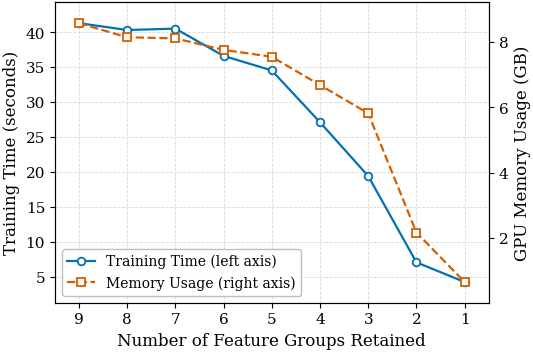

saved: /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_ember2024_xgboost.pdf
saved: /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_ember2024_xgboost.png


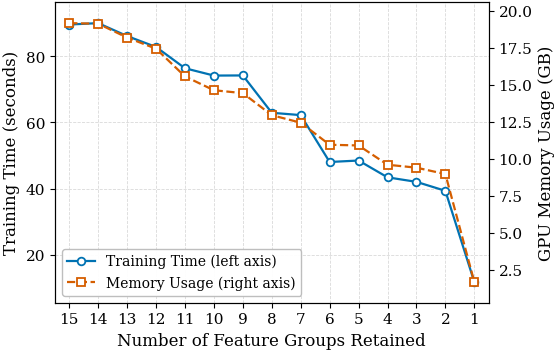

saved: /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_xgboost_ember2018_ember2024.pdf
saved: /content/drive/MyDrive/icml/ember/results/training_cost/training_cost_xgboost_ember2018_ember2024.png


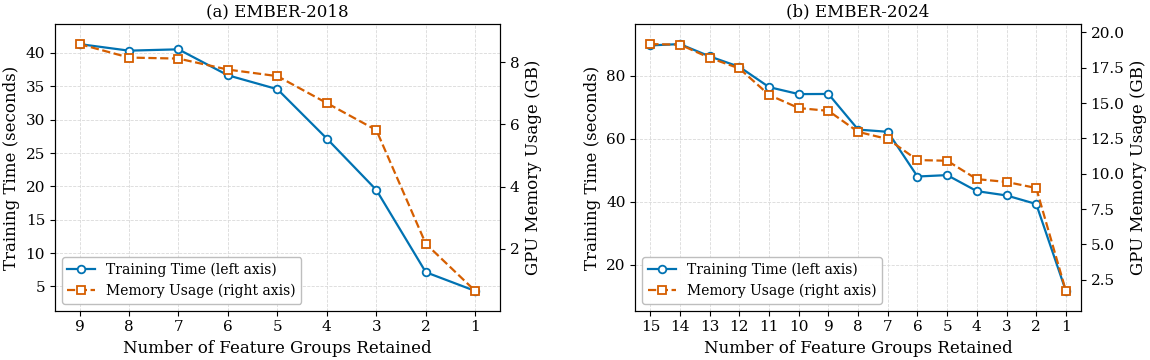

In [ ]:
plt.rcParams.update({
    "font.family": CFG.FIG_FONT_FAMILY, "font.size": CFG.FIG_FONT_SIZE, "mathtext.fontset": "dejavuserif",
    "axes.labelsize": CFG.FIG_FONT_SIZE, "xtick.labelsize": CFG.FIG_FONT_SIZE - 1,
    "ytick.labelsize": CFG.FIG_FONT_SIZE - 1, "legend.fontsize": CFG.FIG_FONT_SIZE - 2,
    "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.bbox": "tight", "savefig.pad_inches": 0.03,
})

_tables = {n: t for n, t in RESULTS.items() if len(t)}
_longest = max(float(t[TIME_COL].max()) for t in _tables.values())
_unit = CFG.TIME_UNIT if CFG.TIME_UNIT in ("seconds", "minutes") else ("minutes" if _longest >= 120 else "seconds")
TIME_DIV, TIME_LABEL = (60.0, "Training Time (minutes)") if _unit == "minutes" else (1.0, "Training Time (seconds)")


def _limits(values):
    lo, hi = float(np.min(values)), float(np.max(values))
    pad = 0.08 * (hi - lo) if hi > lo else 0.08 * max(abs(hi), 1e-9)
    return (0.0 if CFG.Y_AXES_FROM_ZERO else lo - pad), hi + pad


def _legend_place(ax, ax2, lines, width=0.64, height=0.27):
    """The corner of the plot where a legend covers no data point, or None if every corner holds some."""
    pts = np.vstack([ax.transAxes.inverted().transform(axis.transData.transform(np.column_stack(line.get_data())))
                     for axis, line in zip((ax, ax2), lines)])
    boxes = {"upper right": (1 - width, 1 - height, 1, 1), "lower left": (0, 0, width, height),
             "upper left": (0, 1 - height, width, 1), "lower right": (1 - width, 0, 1, height)}
    for corner, (x0, y0, x1, y1) in boxes.items():
        if not ((pts[:, 0] >= x0) & (pts[:, 0] <= x1) & (pts[:, 1] >= y0) & (pts[:, 1] <= y1)).any():
            return corner
    return None


def draw_cost(ax, table, title=None):
    """One dataset: training time on the left axis and memory usage on the right axis."""
    table = table.sort_values("n_groups_retained", ascending=False)
    x = table["n_groups_retained"].to_numpy()
    t, m = table[TIME_COL].to_numpy() / TIME_DIV, table[MEM_COL].to_numpy()
    style = dict(lw=1.6, ms=5.5, mfc="white", mew=1.3)
    ax2 = ax.twinx()
    line_t, = ax.plot(x, t, "-", marker="o", color=CFG.COLOR_TIME, mec=CFG.COLOR_TIME,
                      label="Training Time (left axis)", **style)
    line_m, = ax2.plot(x, m, "--", marker="s", color=CFG.COLOR_MEMORY, mec=CFG.COLOR_MEMORY,
                       label="Memory Usage (right axis)", **style)
    ax.set_xlim(x.max() + 0.5, x.min() - 0.5)              # the full feature set is on the left
    ax.set_xticks(x)
    ax.set_ylim(*_limits(t))
    ax2.set_ylim(*_limits(m))
    ax.set_xlabel("Number of Feature Groups Retained")
    ax.set_ylabel(TIME_LABEL)
    ax2.set_ylabel(MEM_LABEL)
    ax.grid(True, linestyle="--", linewidth=0.6, color="#D9D9D9")
    ax.set_axisbelow(True)
    corner = _legend_place(ax, ax2, (line_t, line_m))
    if corner:                                             # inside the plot, in a corner without data points
        ax2.legend(handles=[line_t, line_m], loc=corner, frameon=True, framealpha=0.95, edgecolor="#BBBBBB")
    else:                                                  # no free corner: in one row above the plot
        ax2.legend(handles=[line_t, line_m], loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False,
                   columnspacing=1.2, handlelength=2.4)
    if title:
        ax.set_title(title, fontsize=CFG.FIG_FONT_SIZE, pad=6 if corner else 28)
    return ax2


def _save(fig, stem):
    for ext in CFG.FIG_FORMATS:
        path = os.path.join(CFG.OUTPUT_DIR, f"{stem}.{ext}")
        fig.savefig(path, dpi=CFG.FIG_DPI)
        print("saved:", path)


for _name, _tab in _tables.items():
    fig, ax = plt.subplots(figsize=CFG.FIG_SIZE)
    draw_cost(ax, _tab)
    _save(fig, f"training_cost_{_name}_xgboost")
    plt.show()

if len(_tables) > 1:
    _names = [n for n in ("ember2018", "ember2024") if n in _tables]
    fig, axes = plt.subplots(1, len(_names), figsize=(CFG.FIG_SIZE[0] * len(_names) + 0.6, CFG.FIG_SIZE[1]))
    for _ax, _name, _tag in zip(axes, _names, "abcd"):
        draw_cost(_ax, _tables[_name], title=f"({_tag}) {DATASET_TITLE[_name]}")
    fig.tight_layout(w_pad=2.5)
    _save(fig, "training_cost_xgboost_" + "_".join(_names))
    plt.show()